# Perceptron from scratch

The Perceptron algorithm is the simplest type of artificial neural network. It is usually used in binary classification problems and it provides the foundation for later developing much larger networks. <br>
In this Lab, we implement the Perceptron algorithm from scratch with Python.The goal is to know: 
<ul>
<li>How to train the network weights for the Perceptron. </li>
<li>How to make predictions with the Perceptron.</li>
<li>How to implement the Perceptron algorithm for a real-world classification problem.</li>
</ul>

### The perceptron

The Perceptron is inspired by the information processing of a single neural cell called a neuron.A neuron accepts input signals via its dendrites, which pass the electrical signal down to the cell body.<br>

In a similar way, the Perceptron receives input signals from examples of training data that we weight and combined in a linear equation called the activation.<br>
<b>
activation = sum(weight_i * x_i) + bias
    </b><br>
The activation is then transformed into an output value or prediction using an activation function, such as the step function (Threshold).<br>
    <b>
        prediction = 1.0 if activation >= 0.0 else 0.0
    </b><br>
    
The Perceptron is a binary classification algorithm (two classes problems) where a linear equation can be used to separate the two classes.<br>

The weights of the Perceptron algorithm are first initialized randomly but they must then be optimized using the training data via stochastic gradient descent.

### Stochastic Gradient Descent

Gradient Descent is the process of minimizing a function by following the gradients of the cost function.<br>

This involves knowing the form of the cost as well as the derivative so that from a given point you know the gradient and can move in that direction, e.g. downhill towards the minimum value. <br>

In machine learning, we can use a technique that evaluates and updates the weights every iteration called stochastic gradient descent to minimize the error of a model on our training data.<br>

The way this optimization algorithm works is that each training instance is shown to the model one at a time. The model makes a prediction for a training instance, the error is calculated and the model is updated in order to reduce the error for the next prediction. <br>

This procedure can be used to find the set of weights in a model that result in the smallest error for the model on the training data. <br>

For the Perceptron algorithm, at each iteration the weights (<b>w</b>) are updated using the equation: <br>
<b>w = w + learning_rate * (expected - predicted) * x</b><br>

Where <b> w</b> is the weight being optimized, <b>learning_rate</b> is a learning rate that you must configure (e.g. 0.01), <b>(expected – predicted)</b> is the prediction error for the model on the training data attributed to the weight and x is the input value.

### Predictions on the Sonar dataset

This is a dataset that describes sonar chirp returns bouncing off different services. It is a binary classification problem that requires a model to differentiate rocks from metal cylinders.

The first step is to develop a function that can make predictions.

This will be needed both in the evaluation of candidate weights values in stochastic gradient descent, and after the model is finalized and we wish to start making predictions on test data or new data.

Below is a function named predict() that predicts an output value for a row given a set of weights.

The first weight is always the bias as it is standalone and not responsible for a specific input value.

In [1]:
#Make a prediction with weights
def predict(row, weights):
	activation = weights[0]
	for i in range(len(row)-1):
		activation += weights[i + 1] * row[i]
	return 1.0 if activation >= 0.0 else 0.0

We will take just a small portion of the dataset to test our prediction function.


We can also use previously prepared weights to make predictions for this dataset.<br>

There are two inputs values (<b>X1</b> and <b>X2</b>) and three weight values (<b>bias</b>, <b>w1</b> and <b>w2</b>). The activation equation we have modeled for this problem is:

<b>activation = (w1 * X1) + (w2 * X2) + bias </b>

Or, with the specific weight values we chose by hand as:

<b>activation = (0.206 * X1) + (-0.234 * X2) + -0.1 </b>

Running this function we get predictions that match the expected output (<b>y</b>) values.

Putting this all together we can test our <b>predict()</b> function below.

In [2]:
def predict(row, weights):
	activation = weights[0]
	for i in range(len(row)-1):
		activation += weights[i + 1] * row[i]
	return 1.0 if activation >= 0.0 else 0.0
 
# test predictions
dataset = [[2.7810836,2.550537003,0],
	[1.465489372,2.362125076,0],
	[3.396561688,4.400293529,0],
	[1.38807019,1.850220317,0],
	[3.06407232,3.005305973,0],
	[7.627531214,2.759262235,1],
	[5.332441248,2.088626775,1],
	[6.922596716,1.77106367,1],
	[8.675418651,-0.242068655,1],
	[7.673756466,3.508563011,1]]
weights = [-0.1, 0.20653640140000007, -0.23418117710000003]
for row in dataset:
	prediction = predict(row, weights)
	print("Expected=%d, Predicted=%d" % (row[-1], prediction))

Expected=0, Predicted=0
Expected=0, Predicted=0
Expected=0, Predicted=0
Expected=0, Predicted=0
Expected=0, Predicted=0
Expected=1, Predicted=1
Expected=1, Predicted=1
Expected=1, Predicted=1
Expected=1, Predicted=1
Expected=1, Predicted=1


### Training Network Weights

We can estimate the weight values for our training data using stochastic gradient descent.

Stochastic gradient descent requires two parameters:
<ul>
    <li><b>Learning Rate: </b> Used to limit the amount each weight is corrected each time it is updated.</li>
    <li><b>Epochs:</b>  The number of times to run through the training data while updating the weight.</li>
</ul>

We update each weight for each row in the training data, each epoch. There are 3 loops we need to perform in the function:
<ol>
    <li>Loop over each epoch.</li>
    <li>Loop over each row in the training data for an epoch.</li>
    <li>Loop over each weight and update it for a row in an epoch.</li>
</ol>
Weights are updated based on the error the model made. The error is calculated as the difference between the expected output value and the prediction made with the candidate weights.

There is one weight for each input attribute, and these are updated in a consistent way, for example:

The bias is updated in a similar way, except without an input as it is not associated with a specific input value:

Now we can put all of this together. Below is a function named <b>train_weights()</b> that calculates weight values for a training dataset using stochastic gradient descent.

In [3]:
# Estimate Perceptron weights using stochastic gradient descent
def train_weights(train, l_rate, n_epoch, verbose=True):
	weights = [0.0 for i in range(len(train[0]))]
	for epoch in range(n_epoch):
		sum_error = 0.0
		for row in train:
			prediction = predict(row, weights)
			error = row[-1] - prediction
			sum_error += error**2
			weights[0] = weights[0] + l_rate * error
			for i in range(len(row)-1):
				weights[i + 1] = weights[i + 1] + l_rate * error * row[i]
		if verbose:
			print('>epoch=%d, lrate=%.3f, error=%.3f' % (epoch, l_rate, sum_error))
	return weights

You can see that we also keep track of the sum of the squared error (a positive value) each epoch. 

We can test this function on the same small contrived dataset from above.

In [4]:
l_rate = 0.1
n_epoch = 5
weights = train_weights(dataset, l_rate, n_epoch)
print(weights)

>epoch=0, lrate=0.100, error=2.000
>epoch=1, lrate=0.100, error=1.000
>epoch=2, lrate=0.100, error=0.000
>epoch=3, lrate=0.100, error=0.000
>epoch=4, lrate=0.100, error=0.000
[-0.1, 0.20653640140000007, -0.23418117710000003]


We use a learning rate of 0.1 and train the model for only 5 epochs, or 5 exposures of the weights to the entire training dataset.

<b>Explain the obtained results.</b>

In [5]:
print('Poids appris [bias, w1, w2] =', weights)
print()
# Vérification : prédictions du perceptron entraîné sur le mini-dataset
n_ok = 0
for row in dataset:
    p = predict(row, weights)
    n_ok += (p == row[-1])
    print('X1=%.3f  X2=%.3f | attendu=%d  prédit=%d' % (row[0], row[1], row[-1], p))
print('\nBien classés : %d / %d' % (n_ok, len(dataset)))

Poids appris [bias, w1, w2] = [-0.1, 0.20653640140000007, -0.23418117710000003]

X1=2.781  X2=2.551 | attendu=0  prédit=0
X1=1.465  X2=2.362 | attendu=0  prédit=0
X1=3.397  X2=4.400 | attendu=0  prédit=0
X1=1.388  X2=1.850 | attendu=0  prédit=0
X1=3.064  X2=3.005 | attendu=0  prédit=0
X1=7.628  X2=2.759 | attendu=1  prédit=1
X1=5.332  X2=2.089 | attendu=1  prédit=1
X1=6.923  X2=1.771 | attendu=1  prédit=1
X1=8.675  X2=-0.242 | attendu=1  prédit=1
X1=7.674  X2=3.509 | attendu=1  prédit=1

Bien classés : 10 / 10


#### Explication des résultats

- **Erreur par époque** : 2.0 → 1.0 → 0.0 → 0.0 → 0.0. À l'époque 0, deux exemples sont mal classés (somme des erreurs² = 2), à l'époque 1 il n'en reste qu'un, et dès l'**époque 2 l'erreur est nulle** : le perceptron classe correctement les 10 exemples. Une fois l'erreur nulle, `error = expected - predicted = 0` pour chaque ligne, donc **les poids ne changent plus** : c'est la convergence.
- **Pourquoi il converge** : les deux classes de ce mini-dataset sont **linéairement séparables** (classe 0 : X1 petit ; classe 1 : X1 grand). Le théorème de convergence du perceptron garantit alors qu'une solution est trouvée en un nombre fini de corrections.
- **Poids obtenus** : `[-0.1, 0.2065, -0.2342]`, exactement les poids « préparés à l'avance » utilisés plus haut. La frontière de décision est la droite `0.2065·X1 − 0.2342·X2 − 0.1 = 0`. Les 10 prédictions concordent avec les valeurs attendues (10/10).
- **Remarque** : seul X1 sépare vraiment les classes (w1 > 0), X2 est peu informatif (w2 plus faible et de signe opposé).

### Modeling the Sonar Dataset

We will now train a Perceptron model using stochastic gradient descent on the Sonar dataset.

The dataset is first loaded, the string values converted to numeric and the output column is converted from strings to the integer values of 0 to 1. This is achieved with helper functions <b>load_csv()</b>, <b>str_column_to_float()</b> and <b>str_column_to_int()</b> to load and prepare the dataset.

In [6]:
from random import seed
from random import randrange
from csv import reader
 
# Load a CSV file
def load_csv(filename):
	dataset = list()
	with open(filename, 'r') as file:
		csv_reader = reader(file)
		for row in csv_reader:
			if not row:
				continue
			dataset.append(row)
	return dataset
 
# Convert string column to float
def str_column_to_float(dataset, column):
	for row in dataset:
		row[column] = float(row[column].strip())
 
# Convert string column to integer
def str_column_to_int(dataset, column):
	class_values = [row[column] for row in dataset]
	unique = set(class_values)
	lookup = dict()
	for i, value in enumerate(unique):
		lookup[value] = i
	for row in dataset:
		row[column] = lookup[row[column]]
	return lookup

We will use k-fold cross validation to estimate the performance of the learned model on unseen data. This means that we will construct and evaluate k models and estimate the performance as the mean model error. Classification accuracy will be used to evaluate each model. These behaviors are provided in the <b>cross_validation_split()</b>, <b>accuracy_metric()</b> and <b>evaluate_algorithm()</b> helper functions.

In [7]:
# Split a dataset into k folds
def cross_validation_split(dataset, n_folds):
	dataset_split = list()
	dataset_copy = list(dataset)
	fold_size = int(len(dataset) / n_folds)
	for i in range(n_folds):
		fold = list()
		while len(fold) < fold_size:
			index = randrange(len(dataset_copy))
			fold.append(dataset_copy.pop(index))
		dataset_split.append(fold)
	return dataset_split
 
# Calculate accuracy percentage
def accuracy_metric(actual, predicted):
	correct = 0
	for i in range(len(actual)):
		if actual[i] == predicted[i]:
			correct += 1
	return correct / float(len(actual)) * 100.0
 
# Evaluate an algorithm using a cross validation split
def evaluate_algorithm(dataset, algorithm, n_folds, *args):
	folds = cross_validation_split(dataset, n_folds)
	scores = list()
	for fold in folds:
		train_set = list(folds)
		train_set.remove(fold)
		train_set = sum(train_set, [])
		test_set = list()
		for row in fold:
			row_copy = list(row)
			test_set.append(row_copy)
			row_copy[-1] = None
		predicted = algorithm(train_set, test_set, *args)
		actual = [row[-1] for row in fold]
		accuracy = accuracy_metric(actual, predicted)
		scores.append(accuracy)
	return scores

We will use the predict() and train_weights() functions created earlier to train the model and a new <b>perceptron()</b> function to tie them together.

In [8]:
# Perceptron Algorithm With Stochastic Gradient Descent
def perceptron(train, test, l_rate, n_epoch):
	predictions = list()
	weights = train_weights(train, l_rate, n_epoch, verbose=False)
	for row in test:
		prediction = predict(row, weights)
		predictions.append(prediction)
	return(predictions)
 
# Test the Perceptron algorithm on the sonar dataset
seed(1)
# load and prepare data
filename = 'sonar.all-data.csv'
dataset = load_csv(filename)
for i in range(len(dataset[0])-1):
	str_column_to_float(dataset, i)
# convert string class to integers
str_column_to_int(dataset, len(dataset[0])-1)
# evaluate algorithm
n_folds = 3
l_rate = 0.01
n_epoch = 500
scores = evaluate_algorithm(dataset, perceptron, n_folds, l_rate, n_epoch)
print('Scores: %s' % scores)
print('Mean Accuracy: %.3f%%' % (sum(scores)/float(len(scores))))

Scores: [76.81159420289855, 69.56521739130434, 72.46376811594203]
Mean Accuracy: 72.947%


A k value of 3 was used for cross-validation, giving each fold 208/3 = 69.3 or just under 70 records to be evaluated upon each iteration. A learning rate of 0.1 and 500 training epochs were chosen with a little experimentation.

## Activities

Try your own configurations and see if you can improve the results.
<ul>
    <li>Tune the learning rate and the number of epochs to get an improved score on the dataset.</li>
    <li>Instead of the perceptron model we've implemented from scratch try using <b>sklearn.linear_model.Perceptron </b> change the hyper-parameters and give the obtained results. What are your remarks?</li>
    <li>Use the evaluation metrics to assess the model's performance </li>
</ul>

### Activité 1 — Régler le taux d'apprentissage et le nombre d'époques (implémentation *from scratch*)

On fait une recherche en grille (*grid search*) avec la même validation croisée à 3 plis et la même graine (`seed(1)`) pour que tous les réglages soient comparés sur les mêmes plis.

In [9]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

lrates = [0.001, 0.01, 0.1, 0.5, 1.0]
epochs = [5, 20, 100, 500, 1000]

res = pd.DataFrame(index=lrates, columns=epochs, dtype=float)
t0 = time.time()
for lr in lrates:
    for ep in epochs:
        seed(1)                      # mêmes plis pour tous les réglages
        sc = evaluate_algorithm(dataset, perceptron, n_folds, lr, ep)
        res.loc[lr, ep] = sum(sc) / len(sc)
print('Temps : %.0f s' % (time.time() - t0))
res.index.name = 'learning rate'; res.columns.name = 'epochs'
print('Accuracy moyenne (%) en validation croisée 3-plis :')
display(res.round(2))
best = res.stack().idxmax()
print('Meilleur réglage : l_rate=%s, n_epoch=%s -> %.2f %%' % (best[0], best[1], res.stack().max()))

Temps : 18 s
Accuracy moyenne (%) en validation croisée 3-plis :


epochs,5,20,100,500,1000
learning rate,,,,,
0.001,71.01,73.91,77.78,72.95,69.57
0.010,71.01,73.91,77.78,72.95,69.57
0.100,71.01,73.91,77.78,72.95,69.57
0.500,71.01,73.91,77.78,72.95,69.57
1.000,71.01,73.91,77.78,72.95,69.57


Meilleur réglage : l_rate=0.001, n_epoch=100 -> 77.78 %


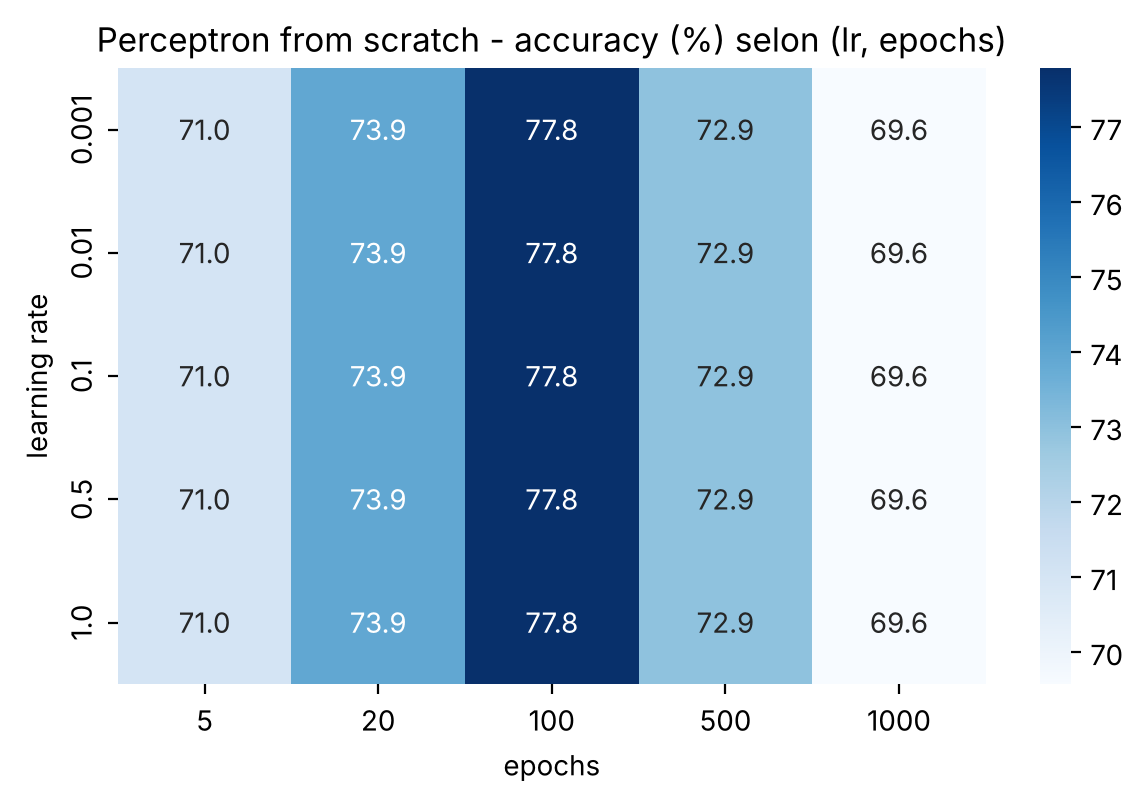

In [10]:
import seaborn as sns
plt.figure(figsize=(7,4))
sns.heatmap(res.astype(float), annot=True, fmt='.1f', cmap='Blues')
plt.title('Perceptron from scratch - accuracy (%) selon (lr, epochs)')
plt.show()

#### Remarques

1. **Le taux d'apprentissage n'a aucun effet ici** : les 5 lignes du tableau sont identiques. Ce n'est pas un bug mais une propriété du perceptron : les poids démarrent à **0** et la prédiction ne dépend que du **signe** de l'activation. Comme `w ← w + lr·(attendu − prédit)·x`, multiplier `lr` par un facteur multiplie tous les poids (biais compris) par ce même facteur, donc ne change jamais le signe de l'activation ni les prédictions. (Avec une initialisation aléatoire ou non nulle, ce ne serait plus vrai.) Le seul vrai hyper-paramètre est donc **le nombre d'époques**.
2. **Nombre d'époques** : l'accuracy monte jusqu'à ≈ **100 époques (77.8 %)**, puis **redescend** (73 % à 500, 69.6 % à 1000). Les données Sonar ne sont **pas linéairement séparables** : le perceptron ne converge jamais (l'erreur ne tombe pas à 0) et les poids continuent d'osciller à chaque exemple mal classé. Le modèle final dépend alors des derniers exemples vus, d'où une performance instable, avec un phénomène proche du surapprentissage au-delà de 100 époques.
3. Meilleur réglage : **n_epoch = 100** (n'importe quel `l_rate`), soit ≈ **+5 points** par rapport au réglage de départ (72.9 %). Avec seulement 3 plis de ~69 exemples, l'estimation reste bruitée (± quelques points).

### Activité 2 — `sklearn.linear_model.Perceptron`

On prépare les données avec NumPy (features = 60 mesures sonar, cible = R/M), on sépare en train/test (70/30, stratifié) et on compare différents hyper-paramètres. On teste aussi l'effet de la **standardisation** des variables.

In [11]:
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

Xs = np.array([row[:-1] for row in load_csv('sonar.all-data.csv')], dtype=float)
ys_raw = np.array([row[-1] for row in load_csv('sonar.all-data.csv')])
ys = (ys_raw == 'M').astype(int)         # M (mine/métal) = 1, R (roche) = 0
print('Dimensions :', Xs.shape, '| classes :', dict(zip(*np.unique(ys_raw, return_counts=True))))

Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.3, random_state=1, stratify=ys)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

configs = {
 'défaut (sans scaling)'                 : Perceptron(random_state=0),
 'défaut + standardisation'              : make_pipeline(StandardScaler(), Perceptron(random_state=0)),
 'eta0=0.01, max_iter=500, scaling'      : make_pipeline(StandardScaler(), Perceptron(eta0=0.01, max_iter=500, tol=None, random_state=0)),
 'eta0=0.1,  max_iter=1000, scaling'     : make_pipeline(StandardScaler(), Perceptron(eta0=0.1, max_iter=1000, tol=None, random_state=0)),
 'penalty=l2, alpha=0.001, scaling'      : make_pipeline(StandardScaler(), Perceptron(penalty='l2', alpha=0.001, random_state=0)),
 'penalty=l2, alpha=0.01, scaling'       : make_pipeline(StandardScaler(), Perceptron(penalty='l2', alpha=0.01, random_state=0)),
 'penalty=l1, alpha=0.001, scaling'      : make_pipeline(StandardScaler(), Perceptron(penalty='l1', alpha=0.001, random_state=0)),
 'penalty=elasticnet, alpha=0.001, scaling': make_pipeline(StandardScaler(), Perceptron(penalty='elasticnet', alpha=0.001, random_state=0)),
 'early_stopping=True, scaling'          : make_pipeline(StandardScaler(), Perceptron(early_stopping=True, random_state=0)),
}
rows = []
for name, m in configs.items():
    m.fit(Xtr, ytr)
    rows.append((name, m.score(Xtr, ytr)*100, m.score(Xte, yte)*100,
                 cross_val_score(m, Xs, ys, cv=cv).mean()*100))
tab = pd.DataFrame(rows, columns=['configuration','acc train %','acc test %','acc CV-5 %']).set_index('configuration')
display(tab.round(2))

Dimensions : (208, 60) | classes : {np.str_('M'): np.int64(111), np.str_('R'): np.int64(97)}


,acc train %,acc test %,acc CV-5 %
configuration,,,
défaut (sans scaling),84.14,73.02,71.66
défaut + standardisation,95.17,73.02,77.44
"eta0=0.01, max_iter=500, scaling",100.00,68.25,73.09
"eta0=0.1, max_iter=1000, scaling",100.00,68.25,73.09
"penalty=l2, alpha=0.001, scaling",86.90,66.67,72.60
"penalty=l2, alpha=0.01, scaling",78.62,69.84,71.72
"penalty=l1, alpha=0.001, scaling",89.66,71.43,75.99
"penalty=elasticnet, alpha=0.001, scaling",85.52,71.43,74.55
"early_stopping=True, scaling",84.83,74.60,73.59


#### Remarques

- **La standardisation est le facteur le plus important** : avec les paramètres par défaut, l'accuracy CV passe de **71.7 % à 77.4 %** en standardisant. Comme les variables Sonar sont déjà toutes comprises entre 0 et 1, le gain reste modéré, mais les variables deviennent comparables entre elles.
- **Surapprentissage** : avec plus d'itérations (`max_iter` = 500 ou 1000, `tol=None`), l'accuracy d'entraînement atteint **100 %** alors que celle de test/CV **baisse** (68 % / 73 %). Le perceptron mémorise le train (60 variables pour ~145 exemples, donc les classes finissent par être séparables dans le train), mais généralise moins bien.
- **Régularisation** : les pénalités `l1`/`elasticnet` (75–76 % en CV) font mieux que `l2` fort (71.7 % avec `alpha=0.01`, qui sous-apprend : train 78.6 %). La pénalité `l1` sélectionne les variables utiles parmi les 60.
- **`early_stopping`** limite le surapprentissage (train 84.8 % / test 74.6 %), mais l'écart avec les autres reste dans le bruit.
- **Comparaison avec notre version from scratch** : à peu près équivalent (72.9 % from scratch avec 500 époques ; 77.4 % pour sklearn standardisé, comparable aux 77.8 % de l'optimum à 100 époques). Les deux restent limités car le perceptron est un classifieur **linéaire**.
- ⚠️ Le jeu de test ne contient que **63 exemples** : un exemple en plus ou en moins change l'accuracy de 1.6 point. Il vaut mieux se fier à la validation croisée (5 plis, dernière colonne) qu'à une seule séparation.

### Activité 3 — Métriques d'évaluation

L'accuracy seule ne suffit pas : on regarde la matrice de confusion, la précision, le rappel, le F1-score et l'AUC (classe positive = **M**, mine/cylindre métallique).

Modèle retenu (meilleure accuracy CV) : défaut + standardisation

Matrice de confusion (lignes = vrai, colonnes = prédit) :
 [[21  8]
 [ 9 25]]

               precision    recall  f1-score   support

   R (roche)       0.70      0.72      0.71        29
   M (métal)       0.76      0.74      0.75        34

    accuracy                           0.73        63
   macro avg       0.73      0.73      0.73        63
weighted avg       0.73      0.73      0.73        63

Accuracy  : 0.730
Précision : 0.758
Rappel    : 0.735
F1        : 0.746
AUC ROC   : 0.814


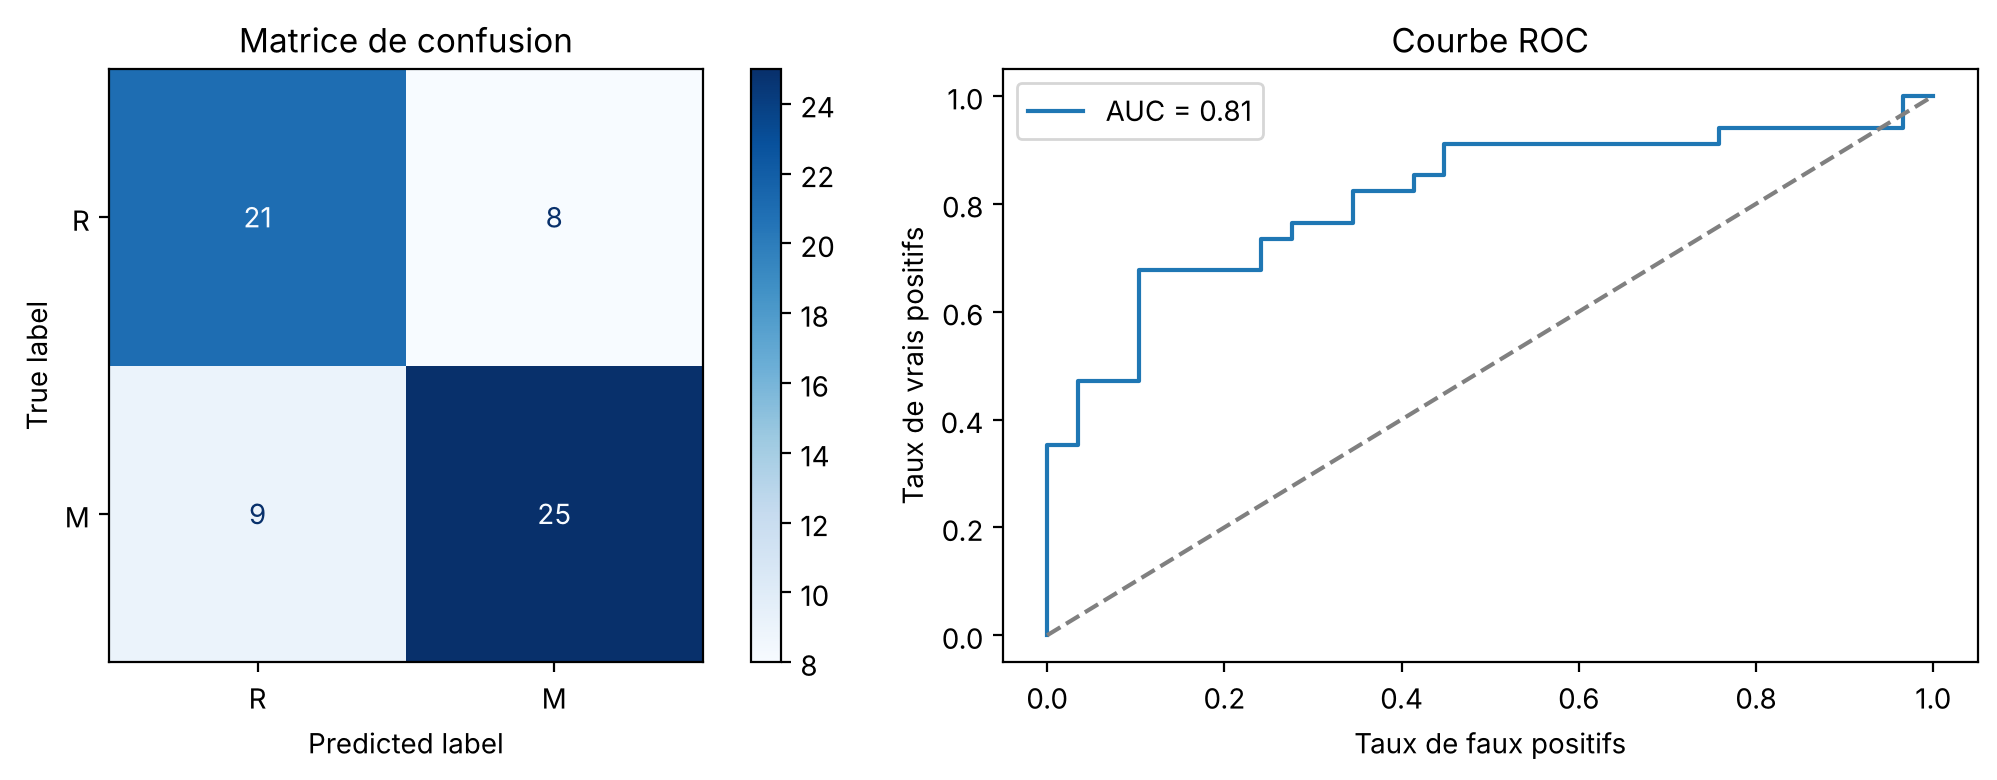

In [12]:
from sklearn.metrics import (confusion_matrix, classification_report, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)

best_name = tab['acc CV-5 %'].idxmax()
print('Modèle retenu (meilleure accuracy CV) :', best_name)
model = configs[best_name].fit(Xtr, ytr)
yp = model.predict(Xte)
scores = model.decision_function(Xte)

print('\nMatrice de confusion (lignes = vrai, colonnes = prédit) :\n', confusion_matrix(yte, yp))
print('\n', classification_report(yte, yp, target_names=['R (roche)', 'M (métal)']))
print('Accuracy  : %.3f' % model.score(Xte, yte))
print('Précision : %.3f' % precision_score(yte, yp))
print('Rappel    : %.3f' % recall_score(yte, yp))
print('F1        : %.3f' % f1_score(yte, yp))
print('AUC ROC   : %.3f' % roc_auc_score(yte, scores))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(yte, yp, display_labels=['R', 'M'], cmap='Blues', ax=ax[0])
ax[0].set_title('Matrice de confusion')
fpr, tpr, _ = roc_curve(yte, scores)
ax[1].plot(fpr, tpr, label='AUC = %.2f' % roc_auc_score(yte, scores)); ax[1].plot([0,1],[0,1],'--',c='gray')
ax[1].set_xlabel('Taux de faux positifs'); ax[1].set_ylabel('Taux de vrais positifs'); ax[1].set_title('Courbe ROC'); ax[1].legend()
plt.tight_layout(); plt.show()

#### Interprétation (modèle retenu : perceptron + standardisation)

- **Matrice de confusion** `[[21, 8], [9, 25]]` : sur 63 sonars, 46 sont bien classés (accuracy **73 %**). Il y a 8 faux positifs (roche prise pour une mine) et 9 faux négatifs (mine non détectée).
- **Précision 0.76** : quand le modèle annonce « métal », il a raison 3 fois sur 4. **Rappel 0.74** : il retrouve 74 % des vrais objets métalliques. **F1 = 0.75**, **AUC = 0.81** (le modèle classe correctement une mine au-dessus d'une roche dans 81 % des paires).
- Les erreurs sont **équilibrées** entre les deux classes (pas de biais vers une classe, le jeu étant presque équilibré : 111 M / 97 R). Dans une application réelle (détection de mines), le **faux négatif** est bien plus grave qu'un faux positif : on privilégierait le rappel en abaissant le seuil de décision.
- **Conclusion** : un perceptron linéaire donne des résultats corrects (~73–77 %), mais un modèle non linéaire (MLP, SVM à noyau, forêt aléatoire) ferait nettement mieux sur ce problème ; c'est précisément l'intérêt du Lab 2.